# 01 Planejar e organizar um fatorial $2^2r$

Queremos investigar como a quantidade de workers e o uso de cache afetam a latência de um serviço. Cada fator terá dois níveis. As quatro combinações receberão $r$ sessões independentes, totalizando $N=4r$ observações.

Todos os dados são artificiais e serão gerados neste notebook com uma semente definida. As tabelas e as figuras descrevem esse cenário. As figuras são salvas em PDF vetorial.


## Objetivo, fatores e resposta

A pergunta é se aumentar os workers e ativar o cache reduzem a latência média. Também queremos saber se o ganho obtido com mais workers depende do estado do cache.

| Fator | Nível baixo $-1$ | Nível alto $+1$ | Hipótese de funcionamento |
| --- | --- | --- | --- |
| A | 2 workers | 8 workers | Mais workers podem reduzir a espera, mas também aumentar a disputa por recursos |
| B | Cache desligado | Cache ligado | O cache pode evitar trabalho repetido e reduzir a latência |

A hipótese de interação é que o cache muda a quantidade de trabalho distribuída entre os workers. Assim, o ganho com mais workers pode ser diferente nos dois estados do cache. Essas expectativas justificam a escolha dos fatores. O resultado dependerá das respostas observadas.

A resposta é a latência média da sessão em milissegundos. A unidade experimental é uma sessão que recebe uma configuração, começa com estado reinicializado e passa pelo mesmo protocolo.


## Protocolo e replicação

| Elemento | Regra do experimento |
| --- | --- |
| Ambiente | Mesmo hardware, versão do serviço e conjunto de dados |
| Carga | 16 clientes concorrentes com a mesma distribuição de requisições |
| Aquecimento | 60 segundos antes da janela medida |
| Medição | 180 segundos por sessão |
| Estado inicial | Reinicializar o processo e o cache antes de cada sessão |
| Registro | Guardar configuração aplicada, ordem efetiva, latência e ocorrência de falhas |

Uma replicação é uma nova sessão independente sob a mesma combinação. As requisições dentro de uma sessão ajudam a medir sua latência, mas compartilham estado e condições de execução. Elas não contam como novas replicações.

O número da replicação identifica a sessão dentro do tratamento. Ele não estabelece pares entre tratamentos. O desenho usado aqui é completamente aleatorizado, sem blocos. Se dias ou máquinas formarem agrupamentos planejados, essa estrutura precisa aparecer no modelo.


In [1]:
from pathlib import Path
from itertools import combinations, product
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

NOME_NOTEBOOK = '01_planejamento_22r'
CONFIANCA = CONFIDENCE_LEVEL = 0.90
ALPHA = 1-CONFIANCA
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
FIGURAS = BASE/'figuras'/NOME_NOTEBOOK
TABELAS = BASE/'tabelas'/NOME_NOTEBOOK
FIGURAS.mkdir(parents=True,exist_ok=True)
TABELAS.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({
    'font.family':'serif','font.serif':['STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':11,'axes.labelsize':11,
    'xtick.labelsize':9,'ytick.labelsize':9,'legend.fontsize':9,
    'figure.dpi':130,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'axes.linewidth':.8,'lines.linewidth':1.4,'lines.markersize':4.5,
    'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})
AZUL='#24577A'
LARANJA='#B76532'
VERDE='#44735B'
CINZA='#707070'
CORES=[AZUL,LARANJA,VERDE,CINZA]
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')

def salvar_figura(fig,nome):
    if any(ax.get_title() or ax.get_title(loc='left') or ax.get_title(loc='right') for ax in fig.axes):
        raise ValueError('A identificação pertence à legenda externa da figura')
    if getattr(fig,'_suptitle',None) is not None:
        raise ValueError('A identificação pertence ao texto')
    w,h=fig.get_size_inches()
    if w>10 or h>10 or w<3 or h<2:
        raise ValueError('Dimensões físicas inadequadas')
    pdf=FIGURAS/f'{nome}.pdf'
    png=FIGURAS/f'{nome}.png'
    fig.savefig(pdf,format='pdf',dpi=600)
    fig.savefig(png,format='png',dpi=180)
    largura=1000 if len(fig.axes)>1 else 820
    display({'image/png':base64.b64encode(png.read_bytes()).decode('ascii')},raw=True,
        metadata={'image/png':{'width':largura,'height':round(largura*h/w)},
                  'fatorial_pdf':str(pdf.relative_to(BASE)),
                  'largura_polegadas':float(w),'altura_polegadas':float(h)})
    plt.close(fig)

def salvar_tabela(tabela,nome,indice=False,colunas_p=None):
    tabela.to_csv(TABELAS/f'{nome}.csv',index=indice)
    copia=tabela.copy()
    if colunas_p:
        for col in colunas_p:
            copia[col]=copia[col].map(lambda p:'' if pd.isna(p) else formatar_p(p))
    display(copia)

def formatar_p(p):
    return '< 1e-300' if p<=0 else f'{p:.4g}'

def decisao_teste(nome,p,contra,sem_evidencia):
    if not np.isfinite(p):
        display(Markdown(f'**{nome}**\n\nO valor-p não está definido para estes dados. A decisão depende do gráfico e das condições do diagnóstico.'))
        return
    if p<=ALPHA:
        texto=f'É significativo porque o valor-p {formatar_p(p)} é menor ou igual a {ALPHA:.2f}. {contra}'
    else:
        texto=f'Não é significativo porque o valor-p {formatar_p(p)} é maior que {ALPHA:.2f}. {sem_evidencia}'
    display(Markdown(f'**{nome}**\n\n{texto}'))

def matriz_sinais(k):
    if not isinstance(k,(int,np.integer)) or not 1<=k<=8:
        raise ValueError('Use entre um e oito fatores no fatorial completo')
    g=2**k
    niveis=2*((np.arange(g)[:,None]>>np.arange(k))&1)-1
    letras=[chr(65+i) for i in range(k)]
    termos=[]
    colunas=[]
    for mascara in range(g):
        ids=[j for j in range(k) if mascara&(1<<j)]
        termos.append(''.join(letras[j] for j in ids) if ids else '0')
        colunas.append(np.prod(niveis[:,ids],axis=1) if ids else np.ones(g))
    return niveis,np.column_stack(colunas),termos

def ajustar(response):
    response=np.asarray(response,dtype=float)
    if response.ndim!=2 or response.shape[0]<2:
        raise ValueError('Use uma matriz com combinações nas linhas e replicações nas colunas')
    g,r=response.shape
    k=int(np.log2(g))
    if 2**k!=g or r<2 or not np.isfinite(response).all():
        raise ValueError('O desenho completo exige 2**k combinações e pelo menos duas replicações finitas')
    niveis,Xc,termos=matriz_sinais(k)
    N=response.size
    nu=g*(r-1)
    medias=response.mean(axis=1)
    q=Xc.T@medias/g
    X=np.repeat(Xc,r,axis=0)
    y=response.ravel()
    ajustados=X@q
    residuos=y-ajustados
    SSE=float(residuos@residuos)
    SST=float(np.sum((y-y.mean())**2))
    MSE=SSE/nu
    if MSE<=np.finfo(float).eps*max(1,float(np.mean(y*y))):
        raise ValueError('O erro puro é nulo ou numericamente desprezível')
    SS=N*q[1:]**2
    se=np.sqrt(MSE)
    sq=se/np.sqrt(N)
    t=q[1:]/sq
    pval=2*stats.t.sf(np.abs(t),nu)
    crit=stats.t.ppf(1-ALPHA/2,nu)
    efeitos=pd.DataFrame({'Termo':termos[1:],'q':q[1:],'EP de q':sq,
        'IC inferior':q[1:]-crit*sq,'IC superior':q[1:]+crit*sq,
        'Efeito 2q':2*q[1:],'t':t,'Valor-p':pval,
        'Significativo':np.where(pval<=ALPHA,'Sim','Não')})
    anova=pd.DataFrame({'Fonte':termos[1:]+['Erro','Total'],
        'SS':np.r_[SS,SSE,SST],'gl':np.r_[np.ones(g-1,dtype=int),nu,N-1],
        'MS':np.r_[SS,MSE,np.nan],'F':np.r_[SS/MSE,np.nan,np.nan],
        'Valor-p':np.r_[pval,np.nan,np.nan]})
    F_global=float(np.sum(SS)/(g-1)/MSE)
    p_global=float(stats.f.sf(F_global,g-1,nu))
    assert np.isclose(SST,SS.sum()+SSE)
    assert np.allclose(Xc.T@Xc,g*np.eye(g))
    assert np.allclose(SS/MSE,t*t)
    return dict(response=response,k=k,g=g,r=r,N=N,nu=nu,Xc=Xc,X=X,niveis=niveis,
        termos=termos,q=q,y=y,medias=medias,ajustados=ajustados,residuos=residuos,
        SSE=SSE,SST=SST,SS=SS,MSE=MSE,se=se,sq=sq,anova=anova,efeitos=efeitos,
        F_global=F_global,p_global=p_global)

def modelo_escrito(res,nomes=None,resposta='y'):
    partes=[f'{res["q"][0]:.4g}']
    for termo,valor in zip(res['termos'][1:],res['q'][1:]):
        produto=''.join('x_{'+letra+'}' for letra in termo)
        partes.append((' + ' if valor>=0 else ' - ')+f'{abs(valor):.4g}'+produto)
    display(Markdown('$$\\widehat{'+resposta+'}='+''.join(partes)+'.$$'))

def mostrar_resultados(res):
    salvar_tabela(res['efeitos'],'efeitos_ic_testes',colunas_p=['Valor-p'])
    for termo,p in zip(res['termos'][1:],res['efeitos']['Valor-p']):
        decisao_teste(f'Efeito q{termo}',p,
            f'Há evidência de que q{termo} difere de zero nas condições do modelo.',
            f'Não há evidência suficiente de que q{termo} difere de zero. Isso não demonstra ausência de efeito.')

def mostrar_anova(res):
    salvar_tabela(res['anova'],'anova',colunas_p=['Valor-p'])
    tabela=pd.DataFrame([{'F global':res['F_global'],'gl numerador':res['g']-1,
        'gl denominador':res['nu'],'Valor-p':res['p_global']}])
    salvar_tabela(tabela,'F_global',colunas_p=['Valor-p'])
    decisao_teste('Teste F global',res['p_global'],
        'Há evidência de que pelo menos um termo do modelo difere de zero.',
        'Não há evidência suficiente de diferença entre as médias das combinações.')

def graficos_efeitos(res,prefixo):
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ids=np.arange(res['g']-1)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
    ax.errorbar(res['q'][1:],ids,xerr=margem,fmt='o',capsize=3,color=AZUL)
    ax.axvline(0,color=CINZA,lw=.8)
    ax.set_yticks(ids,['q'+t for t in res['termos'][1:]])
    ax.set_xlabel('Coeficiente q e IC de 90% ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Termo')
    salvar_figura(fig,prefixo+'_efeitos')

def grafico_variacao(res,prefixo):
    nomes=res['termos'][1:]+['Erro']
    percent=100*np.r_[res['SS'],res['SSE']]/res['SST']
    tabela=pd.DataFrame({'Fonte':nomes,'SS':np.r_[res['SS'],res['SSE']],
                        'Variação alocada (%)':percent})
    salvar_tabela(tabela,prefixo+'_variacao')
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ordem=np.argsort(percent)
    ax.barh(np.asarray(nomes)[ordem],percent[ordem],color=[CINZA if nomes[i]=='Erro' else AZUL for i in ordem])
    ax.set_xlabel('Variação total alocada (%)')
    ax.set_ylabel('Fonte')
    salvar_figura(fig,prefixo+'_variacao')

def graficos_niveis(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    cols=min(2,k)
    rows=int(np.ceil(k/cols))
    tamanho=(5,3) if rows==1 else (5,5)
    fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
    ep=res['se']/np.sqrt(res['N']/2)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*ep
    for j,ax in enumerate(axes.ravel()):
        if j>=k:
            ax.set_visible(False)
            continue
        vals=[res['medias'][res['niveis'][:,j]==a].mean() for a in [-1,1]]
        if com_ic:ax.errorbar([0,1],vals,yerr=margem,fmt='o-',capsize=3,color=AZUL)
        else:ax.plot([0,1],vals,'o-',color=AZUL)
        ax.set_xticks([0,1],niveis_reais[j])
        ax.set_xlabel(nomes[j])
        ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')'+(' e IC de 90%' if com_ic else ''))
        ax.text(.01,1.025,f'({chr(97+j)})',transform=ax.transAxes,ha='left',va='bottom')
        ax.margins(x=.15)
    salvar_figura(fig,prefixo+'_niveis')

def graficos_interacoes(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    paineis=[]
    if k==1:return
    for a,b in combinations(range(k),2):
        outros=[j for j in range(k) if j not in [a,b]]
        for condicao in product([-1,1],repeat=len(outros)):
            paineis.append((a,b,outros,condicao))
    if k==2:paineis.append((1,0,[],()))
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['se']/np.sqrt(res['r'])
    for inicio in range(0,len(paineis),6):
        bloco=paineis[inicio:inicio+6]
        cols=2 if len(bloco)<=4 else 3
        rows=int(np.ceil(len(bloco)/cols))
        tamanho=(5,3) if rows==1 else ((5,5) if cols==2 else (7,5))
        fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
        mapa=[]
        for t,ax in enumerate(axes.ravel()):
            if t>=len(bloco):
                ax.set_visible(False)
                continue
            a,b,outros,condicao=bloco[t]
            cond=np.ones(res['g'],dtype=bool)
            for j,v in zip(outros,condicao):cond&=res['niveis'][:,j]==v
            for nivel,cor in [(-1,AZUL),(1,LARANJA)]:
                ys=[res['medias'][cond&(res['niveis'][:,a]==x)&(res['niveis'][:,b]==nivel)].mean() for x in [-1,1]]
                rotulo=niveis_reais[b][0 if nivel==-1 else 1]
                if com_ic:ax.errorbar([0,1],ys,yerr=margem,fmt='o-',capsize=2.5,label=rotulo,color=cor)
                else:ax.plot([0,1],ys,'o-',label=rotulo,color=cor)
            letra=chr(97+t)
            ax.text(.01,1.025,f'({letra})',transform=ax.transAxes,ha='left',va='bottom')
            ax.set_xticks([0,1],niveis_reais[a])
            ax.set_xlabel(nomes[a])
            ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')')
            ax.margins(x=.15,y=.16)
            ax.legend(frameon=False,title=nomes[b],fontsize=8,title_fontsize=9)
            fixos=', '.join(f'{nomes[j]} em {niveis_reais[j][0 if v==-1 else 1]}' for j,v in zip(outros,condicao))
            mapa.append(f'({letra}) {nomes[a]} e {nomes[b]}'+(', '+fixos if fixos else ''))
        display(Markdown('Painéis do gráfico. '+'. '.join(mapa)+'.'))
        salvar_figura(fig,prefixo+f'_interacoes_{inicio//6+1}')

def grid_residuos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve conter cada índice de observação uma vez')
    fig,axes=plt.subplots(2,2,figsize=(5,5),layout='constrained')
    ax=axes[0,0]
    ax.scatter(res['ajustados'],res['residuos'],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Resposta ajustada ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax=axes[0,1]
    for i in range(res['g']):
        ax.scatter(i+1+np.linspace(-.13,.13,res['r']),res['residuos'].reshape(res['g'],res['r'])[i],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Combinação')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax.set_xticks(np.arange(1,res['g']+1))
    ax=axes[1,0]
    quantis,observados=stats.probplot(res['residuos']/(res['se']*np.sqrt(1-1/res['r'])),dist='norm',fit=False)
    ax.scatter(quantis,observados,s=17,color=AZUL)
    ax.plot([min(quantis),max(quantis)],[min(quantis),max(quantis)],color=CINZA,lw=.8)
    ax.set_xlabel('Quantil normal teórico')
    ax.set_ylabel('Resíduo em\nescala comparável')
    ax=axes[1,1]
    ax.plot(np.arange(1,res['N']+1),res['residuos'][ordem],'o-',markersize=3,lw=.8,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Ordem de execução')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    for i,ax in enumerate(axes.ravel()):
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,ha='left',va='bottom')
    salvar_figura(fig,prefixo+'_residuos')

def _estatistica_ks(amostras):
    amostras=np.atleast_2d(amostras)
    n=amostras.shape[1]
    z=(amostras-amostras.mean(axis=1,keepdims=True))/amostras.std(axis=1,ddof=1,keepdims=True)
    F=stats.norm.cdf(np.sort(z,axis=1))
    return np.maximum(np.max(np.arange(1,n+1)/n-F,axis=1),
                      np.max(F-np.arange(n)/n,axis=1))

def diagnosticos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve ser uma permutação dos índices das observações')
    if res['r']==2:
        W_variancia,p_variancia=np.nan,np.nan
    else:
        W_variancia,p_variancia=stats.levene(*res['response'],center='median')
    e=res['residuos']
    W=float(stats.shapiro(e).statistic)
    D=float(_estatistica_ks(e)[0])
    DW=float(np.sum(np.diff(e[ordem])**2)/np.sum(e*e))
    B=4999
    rng=np.random.default_rng(180042)
    erros=rng.normal(size=(B,res['g'],res['r']))
    simulados=(erros-erros.mean(axis=2,keepdims=True)).reshape(B,res['N'])
    Ws=stats.shapiro(simulados,axis=1).statistic
    Ds=_estatistica_ks(simulados)
    DWs=np.sum(np.diff(simulados[:,ordem],axis=1)**2,axis=1)/np.sum(simulados*simulados,axis=1)
    p_W=(1+np.count_nonzero(Ws<=W))/(B+1)
    p_D=(1+np.count_nonzero(Ds>=D))/(B+1)
    p_DW=min(1,2*min((1+np.count_nonzero(DWs<=DW))/(B+1),
                     (1+np.count_nonzero(DWs>=DW))/(B+1)))
    tabela=pd.DataFrame({'Diagnóstico':['Brown e Forsythe','Shapiro e Wilk','Kolmogorov e Smirnov','Durbin e Watson'],
        'Estatística':[W_variancia,W,D,DW],
        'Valor-p':[p_variancia,p_W,p_D,p_DW],
        'Referência':['F aproximada','Normal no mesmo desenho','Normal no mesmo desenho','Normal independente no mesmo desenho']})
    salvar_tabela(tabela,prefixo+'_diagnosticos',colunas_p=['Valor-p'])
    if res['r']==2:
        display(Markdown('Com duas replicações por combinação, os dois desvios absolutos em relação à mediana são iguais. O teste de Brown e Forsythe fica degenerado. A comparação de dispersões deve usar os gráficos e exige mais replicações para esse teste.'))
    decisao_teste('Homocedasticidade',p_variancia,
        'Há evidência contra a igualdade das variâncias.',
        'Não há evidência suficiente contra a igualdade das variâncias.')
    for nome,p in [('Shapiro e Wilk',p_W),('Kolmogorov e Smirnov',p_D)]:
        decisao_teste(nome,p,'Há evidência contra a normalidade dos erros sob a referência adotada.',
            'Não há evidência suficiente contra a normalidade sob a referência adotada.')
    decisao_teste('Durbin e Watson',p_DW,
        'Há evidência de dependência serial na comparação com a referência independente.',
        'Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.')
    return tabela

def grid_padroes(prefixo):
    rng=np.random.default_rng(180043)
    n=80
    x=np.linspace(-1,1,n)
    iid=rng.normal(0,1,n)
    pos=np.zeros(n)
    neg=np.zeros(n)
    for i in range(1,n):
        pos[i]=.83*pos[i-1]+rng.normal(0,.6)
        neg[i]=-.83*neg[i-1]+rng.normal(0,.6)
    padroes=[iid,pos,neg,2*np.sin(np.linspace(0,5*np.pi,n))+rng.normal(0,.3,n),
        rng.normal(0,np.linspace(.2,2,n)),3*(x*x-x.dot(x)/n)+rng.normal(0,.3,n)]
    fig,axes=plt.subplots(2,3,figsize=(7,5),layout='constrained')
    for i,(ax,e) in enumerate(zip(axes.ravel(),padroes)):
        eixo=np.arange(1,n+1) if i<4 else x
        if i<4:ax.plot(eixo,e,'o-',markersize=2,lw=.7,color=AZUL)
        else:ax.scatter(eixo,e,s=11,color=AZUL)
        ax.axhline(0,color=CINZA,lw=.7)
        ax.set_xlabel('Ordem' if i<4 else 'Valor ajustado')
        ax.set_ylabel('Resíduo ilustrativo')
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,va='bottom')
    salvar_figura(fig,prefixo+'_padroes')

def graficos_comparacao(resultados,rotulos,prefixo):
    fig,axes=plt.subplots(1,len(resultados),figsize=(5,3) if len(resultados)<=2 else (7,3),
                          squeeze=False,layout='constrained')
    for i,(res,rotulo) in enumerate(zip(resultados,rotulos)):
        ax=axes[0,i]
        margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
        ax.errorbar(res['q'][1:],np.arange(res['g']-1),xerr=margem,fmt='o',capsize=3,color=CORES[i%4])
        ax.axvline(0,color=CINZA,lw=.7)
        ax.set_yticks(np.arange(res['g']-1),['q'+t for t in res['termos'][1:]])
        ax.set_xlabel('q e IC de 90% ('+res.get('unidade','u.r.')+')')
        ax.set_ylabel(rotulo)
    salvar_figura(fig,prefixo+'_comparacao')

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def _dados_combinacoes(res, nomes, niveis_reais):
    response = np.asarray(res['response'], dtype=float)
    if response.ndim != 2 or response.shape[0] < 2 or response.shape[1] < 2 or not np.isfinite(response).all():
        raise ValueError('Use respostas finitas com ao menos duas replicações por combinação')
    g, r = response.shape
    k = int(np.log2(g))
    if 2**k != g or len(nomes) != k or len(niveis_reais) != k:
        raise ValueError('Os fatores e os níveis devem corresponder ao fatorial completo')
    if len(set(nomes)) != k or any(len(par) != 2 for par in niveis_reais):
        raise ValueError('Use nomes distintos e dois níveis reais por fator')
    niveis = np.asarray(res['niveis'], dtype=int)
    if niveis.shape != (g, k) or not np.isin(niveis, [-1, 1]).all():
        raise ValueError('A matriz de níveis deve acompanhar as linhas da resposta')
    if np.unique(niveis, axis=0).shape[0] != g:
        raise ValueError('As combinações devem aparecer uma vez na matriz de níveis')
    medias = response.mean(axis=1)
    nu = g * (r - 1)
    mse = float(np.sum((response - medias[:, None])**2) / nu)
    if not np.isfinite(mse) or mse < 0:
        raise ValueError('O erro puro precisa produzir uma variância finita')
    if 'MSE' in res and not np.isclose(float(res['MSE']), mse, rtol=1e-9, atol=1e-12):
        raise ValueError('MSE deve ser o erro puro comum do modelo completo')
    ep = np.sqrt(mse / r)
    quantil = float(stats.t.ppf(0.95, nu))
    margem = quantil * ep
    experimentos = [f'Exp{i + 1}' for i in range(g)]
    codigos = [''.join(chr(65 + j) + ('+' if nivel == 1 else '-')
                       for j, nivel in enumerate(linha)) for linha in niveis]
    desenho = pd.DataFrame({'Experimento': experimentos, 'Combinação': codigos})
    for j, nome in enumerate(nomes):
        desenho[nome] = [str(niveis_reais[j][0 if v == -1 else 1]) for v in niveis[:, j]]
    resumo = desenho.copy()
    resumo['Replicações'] = r
    resumo['Média'] = medias
    resumo['MSE comum'] = mse
    resumo['Graus de liberdade'] = nu
    resumo['EP da média'] = ep
    resumo['Quantil t de 90%'] = quantil
    resumo['IC90 inferior'] = medias - margem
    resumo['IC90 superior'] = medias + margem
    rng = np.random.default_rng(180501)
    jitter = np.vstack([rng.permutation(np.linspace(-0.12, 0.12, r)) for _ in range(g)])
    pontos = pd.DataFrame({
        'Experimento': np.repeat(experimentos, r),
        'Combinação': np.repeat(codigos, r),
        'Replicação': np.tile(np.arange(1, r + 1), g),
        'Resposta': response.ravel(),
        'Média do tratamento': np.repeat(medias, r),
        'Deslocamento horizontal': jitter.ravel(),
        'Posição horizontal': (np.arange(g)[:, None] + jitter).ravel()
    })
    return dict(response=response, g=g, r=r, k=k, niveis=niveis, medias=medias,
                nu=nu, mse=mse, ep=ep, margem=margem, jitter=jitter,
                experimentos=experimentos, codigos=codigos, desenho=desenho,
                resumo=resumo, pontos=pontos, unidade=str(res.get('unidade', 'u.r.')))


def _tabela_niveis(ax, dados, nomes):
    ax.set_axis_off()
    linhas = [[textwrap.fill(str(v), width=10, break_long_words=False)
               for v in dados['desenho'][nome]] for nome in nomes]
    tabela = ax.table(cellText=linhas, rowLabels=nomes,
                      colLabels=dados['experimentos'], cellLoc='center',
                      rowLoc='left', loc='center', bbox=[0, 0, 1, 1])
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8 if dados['g'] <= 4 else 7)
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.45)
        celula.set_edgecolor('#A0A0A0')
        celula.PAD = 0.025
        if linha == 0:
            celula.set_facecolor('#F0F0F0')
        if coluna == -1:
            celula.set_text_props(weight='bold')
    return tabela


def _eixos_combinacoes(dados, nomes, n_paineis, com_tabela, compartilhar_y):
    if n_paineis not in (1, 2):
        raise ValueError('Use um cenário ou dois cenários lado a lado')
    if n_paineis == 1:
        tamanho = (5, 4) if com_tabela else (5, 3)
        if dados['g'] > 8:
            tamanho = (9, 4.5) if com_tabela else (9, 3)
    else:
        tamanho = (7, 4) if com_tabela else (7, 3.5)
    fig = plt.figure(figsize=tamanho, layout='constrained')
    if com_tabela:
        grade = fig.add_gridspec(2, n_paineis, height_ratios=[3.3, 1.1])
    else:
        grade = fig.add_gridspec(1, n_paineis)
    eixos = []
    for i in range(n_paineis):
        eixo = fig.add_subplot(grade[0, i], sharey=eixos[0] if compartilhar_y and i else None)
        eixo.tick_params(axis='both', labelsize=9)
        eixo.tick_params(axis='y', labelleft=True)
        eixos.append(eixo)
    if com_tabela:
        _tabela_niveis(fig.add_subplot(grade[1, :]), dados, nomes)
    return fig, eixos


def _painel_pontos(ax, dados, rotulos_x):
    cores = globals().get('CORES', ['#24577A', '#B76532', '#44735B', '#707070'])
    for i, valores in enumerate(dados['response']):
        ax.scatter(i + dados['jitter'][i], valores, s=24,
                   color=cores[i % len(cores)], alpha=0.80, zorder=3)
        ax.hlines(dados['medias'][i], i - 0.21, i + 0.21, color='black',
                  linewidth=1.8, zorder=5, label='Média do tratamento' if i == 0 else None)
    ax.set_xticks(np.arange(dados['g']), rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Resposta ({dados["unidade"]})')
    ax.margins(y=0.12)
    ax.legend(frameon=False, fontsize=8, loc='best')


def _painel_barras(ax, dados, rotulos_x):
    x = np.arange(dados['g'])
    ax.bar(x, dados['medias'], width=0.62, color='#24577A', alpha=0.84, zorder=2)
    ax.errorbar(x, dados['medias'], yerr=dados['margem'], fmt='none',
                ecolor='black', elinewidth=1.1, capsize=3.0, capthick=1.1, zorder=4)
    for i, media in enumerate(dados['medias']):
        ax.annotate(f'{media:.3g}', xy=(i, media + dados['margem']),
                    xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, clip_on=False)
    ax.set_xticks(x, rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Média e IC de 90% ({dados["unidade"]})')
    ax.margins(y=0.20)


def _gravar_dados_combinacoes(dados, prefixo, rotulos):
    grupos_pontos, grupos_medias = [], []
    for painel, rotulo in zip(dados, rotulos):
        pontos = painel['pontos'].copy()
        medias = painel['resumo'].copy()
        if len(dados) > 1:
            pontos.insert(0, 'Cenário', rotulo)
            medias.insert(0, 'Cenário', rotulo)
        grupos_pontos.append(pontos)
        grupos_medias.append(medias)
    tabelas = {'observacoes': pd.concat(grupos_pontos, ignore_index=True),
               'medias_ic90': pd.concat(grupos_medias, ignore_index=True),
               'niveis': dados[0]['desenho'].copy()}
    if 'TABELAS' in globals():
        pasta = Path(globals()['TABELAS'])
        pasta.mkdir(parents=True, exist_ok=True)
        for sufixo, tabela in tabelas.items():
            tabela.to_csv(pasta / f'{prefixo}_{sufixo}.csv', index=False)
    return tabelas


def _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                               compartilhar_y, com_tabela):
    dados = [_dados_combinacoes(res, nomes, niveis_reais) for res in resultados]
    if not dados or len(dados) != len(rotulos):
        raise ValueError('Informe um rótulo para cada cenário')
    if any(not painel['desenho'].equals(dados[0]['desenho']) for painel in dados[1:]):
        raise ValueError('Os painéis precisam representar as mesmas combinações')
    if compartilhar_y and len({painel['unidade'] for painel in dados}) > 1:
        raise ValueError('Escalas compartilhadas exigem a mesma unidade da resposta')
    com_tabela = dados[0]['k'] >= 3 if com_tabela is None else bool(com_tabela)
    rotulos_x = dados[0]['experimentos'] if com_tabela else dados[0]['codigos']
    if len(dados) == 2:
        fig = plt.figure(figsize=(7, 6) if com_tabela else (7, 5), layout='constrained')
        grade = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.48]) if com_tabela else fig.add_gridspec(2, 2)
        for linha, desenhar in enumerate([_painel_pontos, _painel_barras]):
            primeiro = None
            for coluna, painel in enumerate(dados):
                ax = fig.add_subplot(grade[linha, coluna],
                                     sharey=primeiro if compartilhar_y and coluna else None)
                if coluna == 0:
                    primeiro = ax
                desenhar(ax, painel, rotulos_x)
                ax.tick_params(axis='both', labelsize=9)
                ax.tick_params(axis='y', labelleft=True)
                letra = chr(97 + 2 * linha + coluna)
                ax.text(0.01, 1.045, f'({letra})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if com_tabela:
            _tabela_niveis(fig.add_subplot(grade[2, :]), dados[0], nomes)
        descricoes = [f'Pontos de {rotulos[0]}', f'Pontos de {rotulos[1]}',
                      f'Média e IC de {rotulos[0]}', f'Média e IC de {rotulos[1]}']
        mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(descricoes))
        display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_pontos_medias_ic90')
        return _gravar_dados_combinacoes(dados, prefixo, rotulos)
    for tipo, desenhar in [('pontos', _painel_pontos), ('medias_ic90', _painel_barras)]:
        fig, eixos = _eixos_combinacoes(dados[0], nomes, len(dados), com_tabela, compartilhar_y)
        for i, (ax, painel) in enumerate(zip(eixos, dados)):
            desenhar(ax, painel, rotulos_x)
            if len(dados) > 1:
                ax.text(0.01, 1.045, f'({chr(97 + i)})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if len(dados) > 1:
            mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(rotulos))
            display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_{tipo}')
    return _gravar_dados_combinacoes(dados, prefixo, rotulos)


def graficos_combinacoes(res, nomes, niveis_reais, prefixo, *, com_tabela=None):
    """Gera pontos com médias e barras com IC t individual de 90%."""
    return _gerar_graficos_combinacoes([res], [''], nomes, niveis_reais, prefixo,
                                      compartilhar_y=False, com_tabela=com_tabela)


def graficos_combinacoes_pareadas(resultados, rotulos, nomes, niveis_reais, prefixo,
                                 *, compartilhar_y=True, com_tabela=None):
    """Gera um grid 2 por 2 com versões nas colunas e tipos de gráfico nas linhas."""
    if len(resultados) != 2:
        raise ValueError('Informe exatamente dois cenários para os painéis lado a lado')
    return _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                                      compartilhar_y=compartilhar_y, com_tabela=com_tabela)


## Combinações e sequência planejada

Os níveis codificados $-1$ e $+1$ identificam as duas escolhas de cada fator. Eles não indicam desempenho ruim ou bom. A ordem padrão organiza as combinações e permite conferir os sinais.

Com seis replicações em cada tratamento, o plano contém 24 sessões. Primeiro damos uma identidade a cada sessão. Depois sorteamos a sequência de execução. O identificador permanece o mesmo após o sorteio.


In [2]:
r = 6
rng = np.random.default_rng(1801)
tratamentos = ['A-B-', 'A+B-', 'A-B+', 'A+B+']
configuracoes = pd.DataFrame({
    'tratamento': tratamentos,
    'xA': [-1, 1, -1, 1],
    'xB': [-1, -1, 1, 1],
    'workers': [2, 8, 2, 8],
    'cache': ['Desligado', 'Desligado', 'Ligado', 'Ligado']
})
salvar_tabela(configuracoes, '01_configuracoes')

plano = configuracoes.loc[configuracoes.index.repeat(r)].reset_index(drop=True)
plano.insert(0, 'id_sessao', [f'S{i:02d}' for i in range(1, len(plano) + 1)])
plano['replicacao'] = np.tile(np.arange(1, r + 1), len(configuracoes))
plano = plano.iloc[rng.permutation(len(plano))].reset_index(drop=True)
plano['ordem_planejada'] = np.arange(1, len(plano) + 1)
salvar_tabela(plano[['ordem_planejada', 'id_sessao', 'tratamento', 'replicacao']],
               '02_plano_sorteado')


,tratamento,xA,xB,workers,cache
0,A-B-,-1,-1,2,Desligado
1,A+B-,1,-1,8,Desligado
2,A-B+,-1,1,2,Ligado
3,A+B+,1,1,8,Ligado


,ordem_planejada,id_sessao,tratamento,replicacao
0,1,S24,A+B+,6
1,2,S06,A-B-,6
2,3,S02,A-B-,2
3,4,S09,A+B-,3
4,5,S08,A+B-,2
5,6,S17,A-B+,5
6,7,S16,A-B+,4
7,8,S21,A+B+,3
8,9,S11,A+B-,5
9,10,S18,A-B+,6


## Respostas artificiais e ordem efetiva

Geraremos a resposta de cada sessão em torno de uma média artificial definida para seu tratamento. A variação entre sessões virá de uma distribuição normal com desvio-padrão de 3 ms. Esse mecanismo pertence à simulação e não valida o protocolo de um serviço real.

Na simulação, a execução seguirá o plano sorteado. Por isso a ordem efetiva será igual à planejada. Em uma coleta real, a ordem efetiva deve registrar o que ocorreu, incluindo interrupções e execuções refeitas. Sortear uma ordem depois de observar as respostas não recria a aleatorização do experimento.


In [3]:
media_cenario = {'A-B-': 124.0, 'A+B-': 100.0,
                 'A-B+': 84.0, 'A+B+': 72.0}
registro = plano.copy()
registro['ordem_real'] = np.arange(1, len(registro) + 1)
registro['latencia_ms'] = rng.normal(
    loc=registro['tratamento'].map(media_cenario).to_numpy(),
    scale=3.0
)
salvar_tabela(registro[['ordem_real', 'id_sessao', 'tratamento',
                       'replicacao', 'latencia_ms']].head(12),
               '03_inicio_registro')


,ordem_real,id_sessao,tratamento,replicacao,latencia_ms
0,1,S24,A+B+,6,69.182
1,2,S06,A-B-,6,122.37
2,3,S02,A-B-,2,122.97
3,4,S09,A+B-,3,97.852
4,5,S08,A+B-,2,97.956
5,6,S17,A-B+,5,81.332
6,7,S16,A-B+,4,83.569
7,8,S21,A+B+,3,73.042
8,9,S11,A+B-,5,102.55
9,10,S18,A-B+,6,78.578


## Tabela longa e matriz de respostas

Cada linha da tabela longa representa uma sessão. `id_sessao` permite rastrear a observação. A combinação de tratamento e replicação identifica sua posição na matriz. `ordem_real` permite recuperar a sequência temporal.

O CSV preservará essas colunas. As verificações conferem unicidade, respostas finitas e as seis sessões de cada tratamento. Elas detectam problemas de organização, mas não demonstram independência experimental.


In [4]:
assert registro['id_sessao'].is_unique
assert registro['ordem_real'].is_unique
assert not registro.duplicated(['tratamento', 'replicacao']).any()
assert np.isfinite(registro['latencia_ms']).all()
assert registro.groupby('tratamento').size().eq(r).all()
assert set(registro['tratamento']) == set(tratamentos)

from io import StringIO

csv_registro = registro.to_csv(index=False)
(TABELAS / 'api_planejamento.csv').write_text(csv_registro, encoding='utf-8')
lidos = pd.read_csv(StringIO(csv_registro))
assert len(lidos) == 4 * r
assert lidos['id_sessao'].is_unique
assert np.allclose(lidos['latencia_ms'], registro['latencia_ms'])

matriz = lidos.pivot(index='tratamento', columns='replicacao', values='latencia_ms')
matriz = matriz.reindex(index=tratamentos, columns=np.arange(1, r + 1))
assert not matriz.isna().any().any()
response = matriz.to_numpy(dtype=float)
assert response.shape == (4, r)
salvar_tabela(matriz, '04_respostas_por_tratamento', indice=True)


replicacao,1,2,3,4,5,6
tratamento,,,,,,
A-B-,122.37,122.97,122.33,124.52,124.42,122.37
A+B-,100.75,97.956,97.852,99.92,102.55,99.101
A-B+,81.969,83.236,84.743,83.569,81.332,78.578
A+B+,71.88,70.67,73.042,75.762,69.604,69.182


A primeira linha de `response` contém as sessões de A baixo com B baixo. A última contém A alto com B alto. A posição `response[2, 4]` identifica a replicação de número 5 de A baixo com B alto, pois Python começa a contar em zero.

As linhas da matriz ficam na ordem padrão dos tratamentos. Essa organização facilita as contas fatoriais e não representa o tempo. Para analisar a sequência efetiva, usamos a tabela longa ordenada por `ordem_real`.


In [5]:
colunas = ['ordem_real', 'id_sessao', 'tratamento', 'replicacao', 'latencia_ms']
sequencia = lidos.sort_values('ordem_real')[colunas]
salvar_tabela(sequencia.head(8), '05_sequencia_efetiva')
print(f'A replicação 5 de A-B+ registrou {response[2, 4]:.2f} ms.')


,ordem_real,id_sessao,tratamento,replicacao,latencia_ms
0,1,S24,A+B+,6,69.182
1,2,S06,A-B-,6,122.37
2,3,S02,A-B-,2,122.97
3,4,S09,A+B-,3,97.852
4,5,S08,A+B-,2,97.956
5,6,S17,A-B+,5,81.332
6,7,S16,A-B+,4,83.569
7,8,S21,A+B+,3,73.042


A replicação 5 de A-B+ registrou 81.33 ms.


### Observações e médias por combinação

Cada ponto representa uma sessão. O pequeno deslocamento horizontal permite enxergar valores próximos e não modifica a resposta. O traço preto indica a média do tratamento. A combinação no eixo horizontal não representa a ordem de execução.

As barras mostram as médias e as hastes mostram ICs individuais de 90%. O erro padrão da média de uma combinação é $\sqrt{MSE/r}$, com $MSE=SSE/[g(r-1)]$ e $g=2^k$. Assim,

$$IC_{90}(\mu_i)=\bar y_i\pm t_{0{,}95,\,g(r-1)}\sqrt{\frac{MSE}{r}}.$$

Usamos t porque a variância dos erros é estimada pelas replicações. Com desvio padrão populacional conhecido, usaríamos z e esse desvio no lugar de $\sqrt{MSE}$. Os ICs pressupõem erros normais independentes com variância comum. Eles expressam a incerteza da média e não a dispersão de uma sessão individual. A sobreposição das hastes não substitui o teste de uma diferença entre médias.


In [6]:
res = ajustar(response)
res['unidade'] = 'ms'
nomes = ['Workers', 'Cache']
niveis_reais = [['2', '8'], ['Desligado', 'Ligado']]


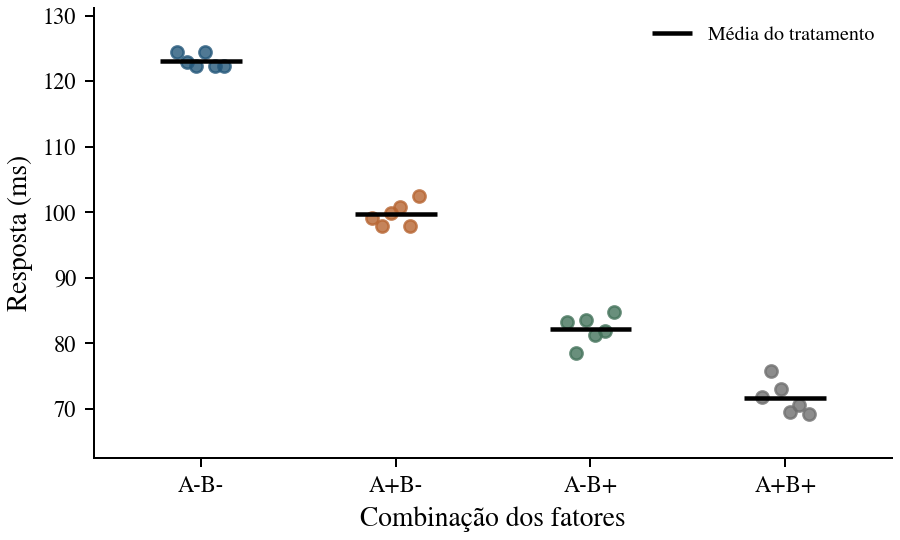

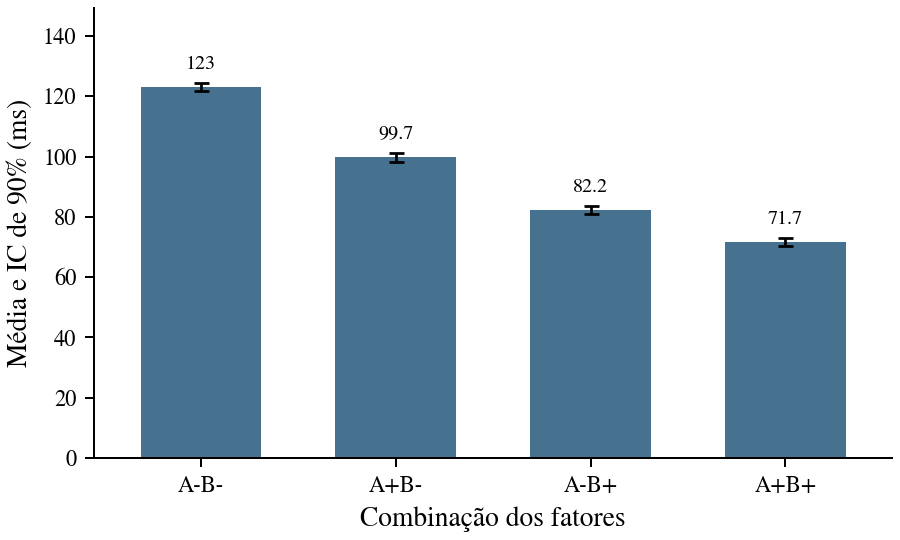

In [7]:
tabela_combinacoes = graficos_combinacoes(res, nomes, niveis_reais, "combinacoes")


## Explorar fatores e níveis

O gráfico de níveis compara as médias em cada escolha de workers e cache. Cada média marginal reúne os tratamentos que compartilham aquele nível.

O gráfico de interação mantém o cache fixo em cada linha e acompanha a mudança de workers. Inclinações diferentes mostram que as mudanças observadas não foram iguais nos dois estados do cache. Os segmentos ligam somente as escolhas medidas. Eles não representam respostas coletadas em níveis intermediários.

Essas figuras são descritivas. Elas orientam a leitura dos efeitos e não substituem a análise da variação nem a avaliação das premissas.


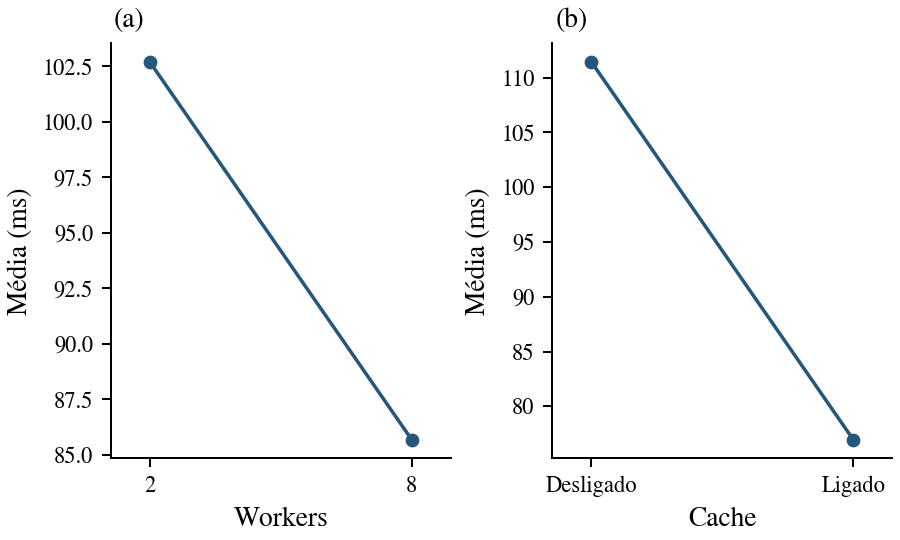

Painéis do gráfico. (a) Workers e Cache. (b) Cache e Workers.

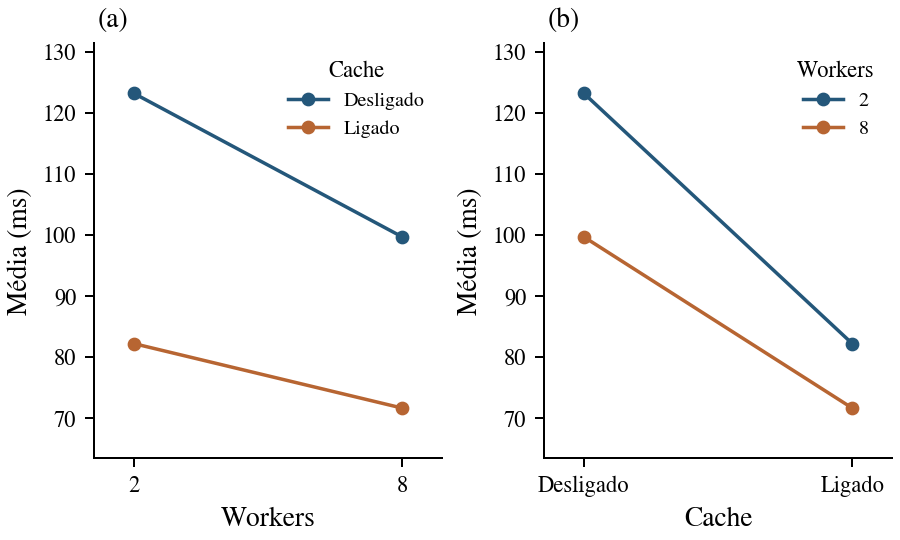

In [8]:
graficos_niveis(res, nomes, niveis_reais, '06_niveis', com_ic=False)
graficos_interacoes(res, nomes, niveis_reais, '07_interacao', com_ic=False)


## Limite da conclusão

O experimento compara duas quantidades de workers e dois estados de cache sob uma carga e um protocolo definidos. A média das sessões não descreve automaticamente latência de cauda, outra carga ou outro equipamento.

Com as observações individuais preservadas, podemos calcular os efeitos, separar a variação entre tratamentos da variação entre sessões e construir o modelo fatorial. A qualidade dessa análise depende da configuração aplicada, das replicações independentes e do registro da execução.


## Referências

Aula de Projeto e Análise de Experimentos, material da disciplina.

Raj Jain. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Capítulos 16 a 18. [Tutorial oficial sobre planejamento de experimentos](https://classes.engineering.wustl.edu/~jain/tutorials/ied_tut.htm).

Douglas C. Montgomery. *Design and Analysis of Experiments*. Referência complementar para definição da unidade experimental, aleatorização e replicação.
